#ITEM 0


In [114]:
from scipy.stats import skew
import pandas as pd
import numpy as np


In [115]:
from google.colab import files

uploaded = files.upload()


In [116]:
Xtrain = pd.read_csv('/content/solTrainX.txt', sep='\t')
Xtest = pd.read_csv('/content/solTestX.txt', sep='\t')
Ytrain = pd.read_csv('/content/solTrainY.txt', sep='\t', index_col=0).iloc[:, 0]
Ytest = pd.read_csv('/content/solTestY.txt', sep='\t', index_col=0).iloc[:, 0]

print(Xtrain.shape, Xtest.shape)
print(Ytrain.shape, Ytest.shape)

Xtrain.isna().sum().sum() # Deve ser zero


(951, 228) (316, 228)
(951,) (316,)


np.int64(0)

In [117]:
"""
As fingerprints começam com "FP". Para separá-las, usamos a ideia do número de
valores distintos
"""
colunas_fp = [c for c in Xtrain.columns if c.startswith('FP')]
colunas_outras = [c for c in Xtrain.columns if not c.startswith('FP')]

print(len(colunas_fp), len(colunas_outras))
print(Xtrain[colunas_outras].nunique().sort_values())




208 20
NumSulfer              5
NumNitrogen            7
NumDblBonds            8
NumRings               8
NumChlorine           11
NumHalogen            11
NumOxygen             11
NumRotBonds           15
NumAromaticBonds      16
NumMultBonds          25
NumCarbon             28
NumNonHAtoms          36
NumNonHBonds          39
NumHydrogen           41
NumAtoms              66
NumBonds              72
SurfaceArea1         252
SurfaceArea2         287
HydrophilicFactor    369
MolWeight            646
dtype: int64


In [118]:
colunas_cont = ['SurfaceArea1', 'SurfaceArea2', 'HydrophilicFactor', 'MolWeight']
colunas_contagem = [c for c in colunas_outras if c not in colunas_cont]
print(len(colunas_contagem), len(colunas_cont)) #Deve dar 16 4


16 4


In [119]:
def tabela_assimetria(df, grupos):
  linhas = []
  for nome_grupo, colunas in grupos.items():
    for col in colunas:
      linhas.append({
          'coluna': col,
          'grupo': nome_grupo,
          'skewness': skew(df[col], bias=False),
          'prop_ou_min_max': df[col].mean() if nome_grupo == 'FP' else None

      })
  return pd.DataFrame(linhas).set_index('coluna')

grupos = {'FP': colunas_fp, 'contagem':colunas_contagem, 'continua':colunas_cont}
tab = tabela_assimetria(Xtrain, grupos)

In [120]:
print(tab.groupby('grupo')['skewness'].describe())
print(tab['skewness'].isna().sum())


          count      mean       std       min       25%       50%       75%  \
grupo                                                                         
FP        208.0  2.020663  1.244991 -2.080051  1.194281  2.191898  3.001292   
contagem   16.0  1.586850  0.898435  0.671298  0.988694  1.361984  1.628588   
continua    4.0  1.898334  1.051653  0.989945  1.355516  1.597113  2.139931   

               max  
grupo               
FP        4.850795  
contagem  3.847603  
continua  3.409164  
0


In [121]:
fp_tab = tab[tab['grupo'] == 'FP'].copy()
fp_tab['p'] = Xtrain[colunas_fp].mean()   # proporção de 1s

# Skew previsto pela fórmula (versão sem correção), para comparar
fp_tab['skew_formula'] = (1 - 2*fp_tab['p']) / np.sqrt(fp_tab['p'] * (1 - fp_tab['p']))

print(fp_tab.sort_values('skewness')[['p', 'skewness', 'skew_formula']].iloc[[0, 1, 2, -3, -2, -1]])
print(fp_tab[['skewness', 'skew_formula']].corr())

               p  skewness  skew_formula
coluna                                  
FP015   0.860147 -2.080051     -2.076769
FP087   0.726604 -1.018445     -1.016838
FP082   0.713985 -0.948552     -0.947055
FP200   0.049422  4.164219      4.157648
FP199   0.047319  4.270893      4.264153
FP154   0.037855  4.850795      4.843141
              skewness  skew_formula
skewness           1.0           1.0
skew_formula       1.0           1.0


In [122]:
cols_nao_fp = colunas_contagem + colunas_cont
print(Xtrain[cols_nao_fp].agg(['min', 'max']).T.join(tab['skewness']).sort_values('skewness', ascending=False))

                      min      max  skewness
NumSulfer           0.000    4.000  3.847603
HydrophilicFactor  -0.985   13.483  3.409164
NumChlorine         0.000   10.000  3.182961
NumHalogen          0.000   10.000  2.695740
NumOxygen           0.000   13.000  1.774490
SurfaceArea1        0.000  331.940  1.716853
NumRotBonds         0.000   16.000  1.579954
NumNitrogen         0.000    6.000  1.556549
SurfaceArea2        0.000  331.940  1.477373
NumAtoms            5.000   94.000  1.366619
NumBonds            4.000   97.000  1.362195
NumDblBonds         0.000    7.000  1.361773
NumHydrogen         0.000   47.000  1.263536
NumRings            0.000    7.000  1.035710
NumNonHAtoms        2.000   47.000  0.994647
MolWeight          46.090  665.810  0.989945
NumNonHBonds        1.000   50.000  0.970835
NumCarbon           1.000   33.000  0.928804
NumAromaticBonds    0.000   25.000  0.796889
NumMultBonds        0.000   25.000  0.671298


In [123]:
zeros = (Xtrain[cols_nao_fp] == 0).mean().rename('prop_zeros')
print(zeros.sort_values(ascending=False).to_frame().join(tab['skewness']).head(8))

                  prop_zeros  skewness
NumSulfer           0.872766  3.847603
NumChlorine         0.788644  3.182961
NumHalogen          0.720294  2.695740
NumNitrogen         0.574132  1.556549
NumDblBonds         0.449001  1.361773
NumAromaticBonds    0.420610  0.796889
NumOxygen           0.341746  1.774490
NumRotBonds         0.286015  1.579954


In [124]:
from sklearn.preprocessing import PowerTransformer
import matplotlib.pyplot as plt

pt = PowerTransformer(method='yeo-johnson', standardize=False)

X_train_t = Xtrain.copy()
X_test_t  = Xtest.copy()
X_train_t[cols_nao_fp] = pt.fit_transform(Xtrain[cols_nao_fp])   # aprende lambda no treino
X_test_t[cols_nao_fp]  = pt.transform(Xtest[cols_nao_fp])        # só aplica no teste

comp = pd.DataFrame({
    'antes':  [skew(Xtrain[c],   bias=False) for c in cols_nao_fp],
    'depois': [skew(X_train_t[c], bias=False) for c in cols_nao_fp],
    'lambda': pt.lambdas_
}, index=cols_nao_fp)
print(comp.sort_values('antes', ascending=False).round(2))

                   antes  depois  lambda
NumSulfer           3.85    2.24   -9.77
HydrophilicFactor   3.41    0.25   -0.32
NumChlorine         3.18    1.42   -3.63
NumHalogen          2.70    1.01   -2.53
NumOxygen           1.77    0.04   -0.17
SurfaceArea1        1.72   -0.24    0.35
NumRotBonds         1.58    0.02   -0.08
NumNitrogen         1.56    0.43   -1.28
SurfaceArea2        1.48   -0.25    0.37
NumAtoms            1.37    0.00    0.05
NumBonds            1.36    0.01    0.11
NumDblBonds         1.36    0.16   -0.58
NumHydrogen         1.26    0.03    0.33
NumRings            1.04    0.00   -0.01
NumNonHAtoms        0.99   -0.00    0.05
MolWeight           0.99   -0.00    0.00
NumNonHBonds        0.97   -0.01    0.15
NumCarbon           0.93   -0.00    0.25
NumAromaticBonds    0.80   -0.08    0.13
NumMultBonds        0.67   -0.14    0.36


25878 47 176
                  a             b         r     abs_r
21500         FP134     NumSulfer  1.000000  1.000000
18612         FP107   NumChlorine  0.999125  0.999125
25708      NumAtoms      NumBonds  0.997033  0.997033
2002          FP009    NumHalogen  0.995921  0.995921
11487         FP058         FP203  0.994812  0.994812
11492         FP058         FP208  0.994770  0.994770
25726  NumNonHAtoms  NumNonHBonds  0.994681  0.994681
25557         FP203         FP208  0.989609  0.989609
6722          FP032         FP183  0.984893  0.984893
2658          FP013         FP014  0.980962  0.980962
8638          FP042         FP194  0.980885  0.980885
12339         FP063   NumNitrogen  0.978498  0.978498
6572          FP032         FP033  0.968811  0.968811
9344          FP046         FP166  0.964591  0.964591
161           FP001         FP163  0.962666  0.962666


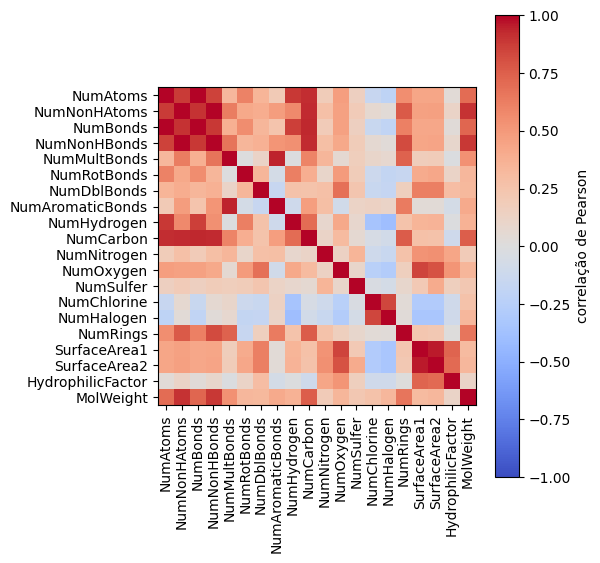

In [125]:
corr = X_train_t.corr()
iu = np.triu_indices_from(corr, k=1)
pares = pd.DataFrame({'a': corr.columns[iu[0]], 'b': corr.columns[iu[1]], 'r': corr.values[iu]})
pares['abs_r'] = pares['r'].abs()

print(len(pares), (pares.abs_r > 0.9).sum(), (pares.abs_r > 0.75).sum())
print(pares.sort_values('abs_r', ascending=False).head(15))

# Mapa de calor só dos 20 descritores não binários
plt.figure(figsize=(6, 6))
plt.imshow(corr.loc[cols_nao_fp, cols_nao_fp], cmap='coolwarm', vmin=-1, vmax=1)
plt.xticks(range(20), cols_nao_fp, rotation=90); plt.yticks(range(20), cols_nao_fp)
plt.colorbar(label='correlação de Pearson'); plt.tight_layout(); plt.show()

                  pearson  spearman     grupo  abs_p
MolWeight          -0.659    -0.685  continua  0.659
NumCarbon          -0.607    -0.674  contagem  0.607
NumNonHBonds       -0.585    -0.632  contagem  0.585
NumNonHAtoms       -0.583    -0.630  contagem  0.583
FP076              -0.538    -0.531        FP  0.538
FP089              -0.501    -0.466        FP  0.501
NumRings           -0.481    -0.509  contagem  0.481
FP044              -0.477    -0.354        FP  0.477
NumMultBonds       -0.476    -0.480  contagem  0.476
NumBonds           -0.459    -0.548  contagem  0.459
NumAtoms           -0.436    -0.520  contagem  0.436
FP172              -0.432    -0.389        FP  0.432
NumAromaticBonds   -0.425    -0.458  contagem  0.425
FP112              -0.423    -0.403        FP  0.423
FP092              -0.403    -0.390        FP  0.403
          count   mean    std    min    25%    50%    75%    max
grupo                                                           
FP        208.0  0.122

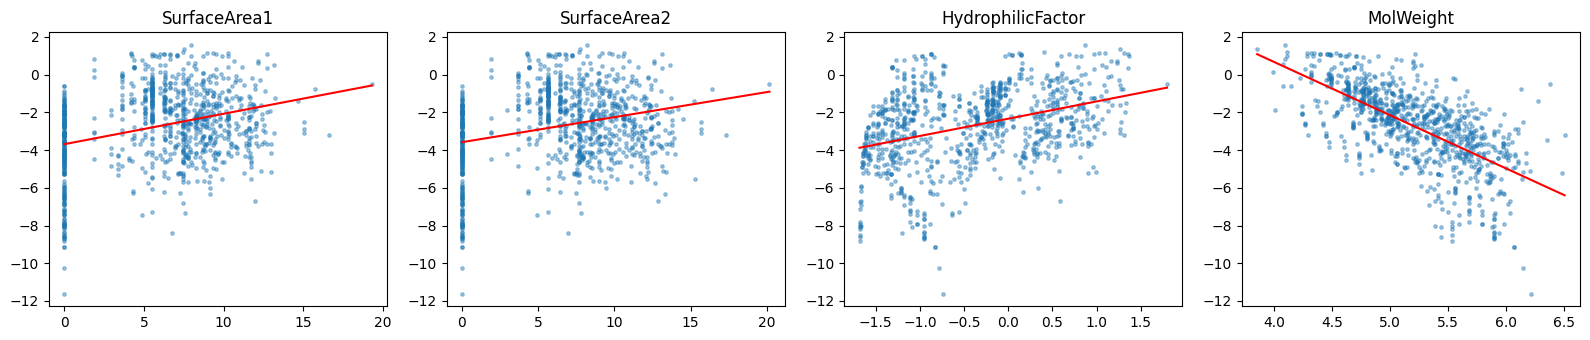

In [126]:
y = pd.Series(Ytrain.values, index=X_train_t.index)   # alinha por posição

res = pd.DataFrame({
    'pearson':  X_train_t.corrwith(y),
    'spearman': X_train_t.corrwith(y, method='spearman')
})
res['grupo'] = tab['grupo']
res['abs_p'] = res['pearson'].abs()

print(res.sort_values('abs_p', ascending=False).head(15).round(3))
print(res.groupby('grupo')['abs_p'].describe().round(3))

# Dispersão das 4 contínuas contra a solubilidade
fig, axs = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, c in zip(axs, colunas_cont):
    ax.scatter(X_train_t[c], y, s=6, alpha=0.4)
    m, b = np.polyfit(X_train_t[c], y, 1)
    xs = np.linspace(X_train_t[c].min(), X_train_t[c].max(), 100)
    ax.plot(xs, m*xs + b, color='red'); ax.set_title(c)
plt.tight_layout(); plt.show()

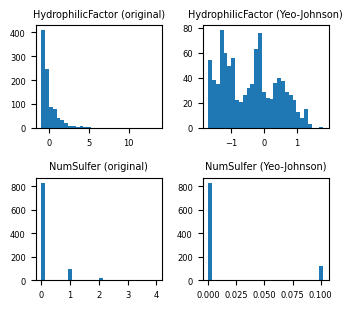

In [127]:
fig, axs = plt.subplots(2, 2, figsize=(3.5, 3.2))   # 3.5 pol = largura de uma coluna IEEE
for i, col in enumerate(['HydrophilicFactor', 'NumSulfer']):
    axs[i, 0].hist(Xtrain[col],   bins=30); axs[i, 0].set_title(f'{col} (original)',     fontsize=7)
    axs[i, 1].hist(X_train_t[col], bins=30); axs[i, 1].set_title(f'{col} (Yeo-Johnson)', fontsize=7)
for ax in axs.ravel():
    ax.tick_params(labelsize=6)
plt.tight_layout()
plt.savefig('fig_assimetria.pdf', bbox_inches='tight')   # PDF mantém a qualidade vetorial

#Item 1


In [128]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate

Xtr = X_train_t.values.astype(float)
Xte = X_test_t.values.astype(float)
ytr = Ytrain.values.astype(float)
yte = Ytest.values.astype(float)

def rmse(y, p):
    return float(np.sqrt(np.mean((y - p) ** 2)))

def r2(y, p):
    return float(1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2))

def add_intercepto(X):
    return np.column_stack([np.ones(len(X)), X])

In [129]:
def ols_normal(X, y):
    A = add_intercepto(X)
    return np.linalg.solve(A.T @ A, A.T @ y)       # resolve AᵀA β = Aᵀy, sem inverter explicitamente

def ols_lstsq(X, y):
    A = add_intercepto(X)
    return np.linalg.lstsq(A, y, rcond=None)[0]

def prever(X, beta):
    return add_intercepto(X) @ beta

print('número de condição:', np.linalg.cond(add_intercepto(Xtr)))

número de condição: 1833312.90543187


In [130]:
for nome, ajustar in [('equações normais', ols_normal), ('lstsq', ols_lstsq)]:
    beta = ajustar(Xtr, ytr)
    print(nome,
          '| treino RMSE:', round(rmse(ytr, prever(Xtr, beta)), 4),
          '| teste RMSE:',  round(rmse(yte, prever(Xte, beta)), 4),
          '| teste R2:',    round(r2(yte, prever(Xte, beta)), 4))

equações normais | treino RMSE: 0.49 | teste RMSE: 0.743 | teste R2: 0.8718
lstsq | treino RMSE: 0.49 | teste RMSE: 0.743 | teste R2: 0.8718


In [131]:
sk = LinearRegression().fit(Xtr, ytr)
p_sk = sk.predict(Xte)
beta_l = ols_lstsq(Xtr, ytr)

print('sklearn | teste RMSE:', round(rmse(yte, p_sk), 4), '| R2:', round(r2(yte, p_sk), 4))
print('maior diferença nas predições (lstsq vs sklearn):', np.max(np.abs(p_sk - prever(Xte, beta_l))))
print('maior diferença nos coeficientes:', np.max(np.abs(np.r_[sk.intercept_, sk.coef_] - beta_l)))

sklearn | teste RMSE: 0.743 | R2: 0.8718
maior diferença nas predições (lstsq vs sklearn): 1.6338042030383804e-12
maior diferença nos coeficientes: 2.0108927856199443e-09


In [132]:
def criar_folds(n, k, semente):
    indices = np.random.default_rng(semente).permutation(n)
    partes = np.array_split(indices, k)
    return [(np.concatenate([partes[j] for j in range(k) if j != i]), partes[i]) for i in range(k)]

def cv_ols(X, y, folds):
    rmses, r2s = [], []
    for idx_tr, idx_va in folds:
        beta = ols_lstsq(X[idx_tr], y[idx_tr])
        p = prever(X[idx_va], beta)
        rmses.append(rmse(y[idx_va], p))
        r2s.append(r2(y[idx_va], p))
    return np.array(rmses), np.array(r2s)

folds = criar_folds(len(ytr), 10, semente=42)
rmse_cv, r2_cv = cv_ols(Xtr, ytr, folds)
print('CV 10-fold | RMSE: %.4f (dp %.4f) | R2: %.4f' % (rmse_cv.mean(), rmse_cv.std(ddof=1), r2_cv.mean()))

np.save('folds_idx.npy', np.array([(a, b) for a, b in folds], dtype=object), allow_pickle=True)

CV 10-fold | RMSE: 0.7279 (dp 0.0668) | R2: 0.8653


In [133]:
cv_sk = cross_validate(LinearRegression(), Xtr, ytr, cv=folds,
                       scoring=('neg_root_mean_squared_error', 'r2'))
rmse_sk = -cv_sk['test_neg_root_mean_squared_error']
print('sklearn CV | RMSE: %.4f | R2: %.4f' % (rmse_sk.mean(), cv_sk['test_r2'].mean()))
print('maior diferença por fold (RMSE):', np.max(np.abs(rmse_sk - rmse_cv)))

sklearn CV | RMSE: 0.7279 | R2: 0.8653
maior diferença por fold (RMSE): 2.3825608153060784e-11


In [134]:
sem_embaralhar = [(np.setdiff1d(np.arange(len(ytr)), p), p) for p in np.array_split(np.arange(len(ytr)), 10)]
rmse_ns, r2_ns = cv_ols(Xtr, ytr, sem_embaralhar)
print('SEM embaralhar | RMSE: %.4f | R2: %.4f' % (rmse_ns.mean(), r2_ns.mean()))
print('R2 por fold:', np.round(r2_ns, 2))

SEM embaralhar | RMSE: 0.7618 | R2: -3.4845
R2 por fold: [ -4.8    0.75   0.85  -9.93  -2.12 -10.34  -5.69   0.71  -4.59   0.3 ]


#ITEM 2


In [135]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline

def padronizar_ajustar(X):
    mu = X.mean(axis=0)
    sd = X.std(axis=0)
    sd[sd == 0] = 1.0              # colunas constantes no fold: evita divisão por zero
    return mu, sd

def ridge_ajustar(X, y, lam):
    mu, sd = padronizar_ajustar(X)
    Z = (X - mu) / sd
    ym = y.mean()
    beta = np.linalg.solve(Z.T @ Z + lam * np.eye(Z.shape[1]), Z.T @ (y - ym))
    return {'beta': beta, 'mu': mu, 'sd': sd, 'ym': ym}

def ridge_prever(modelo, X):
    return ((X - modelo['mu']) / modelo['sd']) @ modelo['beta'] + modelo['ym']

In [136]:
m0 = ridge_ajustar(Xtr, ytr, 1e-8)
print('λ≈0, RMSE teste:', round(rmse(yte, ridge_prever(m0, Xte)), 4))   # deve ser ≈ 0.743 (o do OLS)

λ≈0, RMSE teste: 0.743


In [137]:
lambdas = np.logspace(-2, 3, 25)

def cv_ridge(X, y, folds, lambdas):
    R = np.zeros((len(lambdas), len(folds)))
    Q = np.zeros_like(R)
    for j, (idx_tr, idx_va) in enumerate(folds):
        for i, lam in enumerate(lambdas):
            m = ridge_ajustar(X[idx_tr], y[idx_tr], lam)
            p = ridge_prever(m, X[idx_va])
            R[i, j] = rmse(y[idx_va], p)
            Q[i, j] = r2(y[idx_va], p)
    return R, Q

R, Q = cv_ridge(Xtr, ytr, folds, lambdas)
rmse_medio = R.mean(axis=1)
i_melhor = rmse_medio.argmin()
lam_otimo = lambdas[i_melhor]
print('λ ótimo: %.2f | RMSE CV: %.4f (dp %.4f) | R2 CV: %.4f' %
      (lam_otimo, rmse_medio[i_melhor], R[i_melhor].std(ddof=1), Q.mean(axis=1)[i_melhor]))

λ ótimo: 34.81 | RMSE CV: 0.6859 (dp 0.0406) | R2 CV: 0.8822


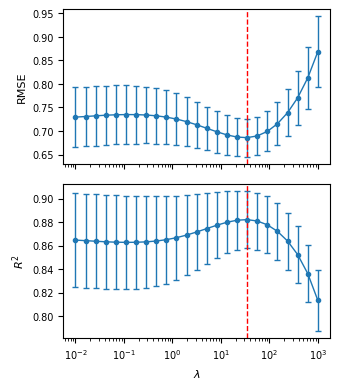

In [138]:
fig, axs = plt.subplots(2, 1, figsize=(3.5, 4), sharex=True)
for ax, M, rotulo in [(axs[0], R, 'RMSE'), (axs[1], Q, '$R^2$')]:
    ax.errorbar(lambdas, M.mean(axis=1), yerr=M.std(axis=1, ddof=1), fmt='o-', ms=3, lw=1, capsize=2)
    ax.axvline(lam_otimo, color='red', ls='--', lw=1)
    ax.set_xscale('log'); ax.set_ylabel(rotulo, fontsize=8); ax.tick_params(labelsize=7)
axs[1].set_xlabel('$\\lambda$', fontsize=8)
plt.tight_layout()
plt.savefig('fig_cv_ridge.pdf', bbox_inches='tight')
plt.show()

In [139]:
modelo_final = ridge_ajustar(Xtr, ytr, lam_otimo)
p_teste = ridge_prever(modelo_final, Xte)
print('treino RMSE: %.4f' % rmse(ytr, ridge_prever(modelo_final, Xtr)))
print('teste  RMSE: %.4f | R2: %.4f' % (rmse(yte, p_teste), r2(yte, p_teste)))

treino RMSE: 0.5467
teste  RMSE: 0.7171 | R2: 0.8806


In [140]:
R_sk = np.zeros_like(R)
for k, lam in enumerate(lambdas):
    cv = cross_validate(make_pipeline(StandardScaler(), Ridge(alpha=lam)), Xtr, ytr,
                        cv=folds, scoring='neg_root_mean_squared_error')
    R_sk[k] = -cv['test_score']
print('maior diferença no perfil de CV:', np.abs(R_sk - R).max())

sk = make_pipeline(StandardScaler(), Ridge(alpha=lam_otimo)).fit(Xtr, ytr)
p_sk = sk.predict(Xte)
print('sklearn teste | RMSE: %.4f | R2: %.4f' % (rmse(yte, p_sk), r2(yte, p_sk)))
print('maior diferença nas predições de teste:', np.abs(p_sk - p_teste).max())

maior diferença no perfil de CV: 7.192024753521764e-13
sklearn teste | RMSE: 0.7171 | R2: 0.8806
maior diferença nas predições de teste: 2.5757174171303632e-14


#ITEM 3

In [141]:
from sklearn.cross_decomposition import PLSRegression

def pls_ajustar(X, y, k):
    mu, sd = padronizar_ajustar(X)
    Xk = (X - mu) / sd
    ym = y.mean()
    yk = y - ym
    W, P, Q = [], [], []
    for _ in range(k):
        w = Xk.T @ yk
        w /= np.linalg.norm(w)          # direção de máxima covariância com y
        t = Xk @ w                       # escore da componente
        tt = t @ t
        p = Xk.T @ t / tt                # carga em X
        q = yk @ t / tt                  # carga em y
        Xk = Xk - np.outer(t, p)         # deflação de X
        yk = yk - t * q                  # deflação de y
        W.append(w); P.append(p); Q.append(q)
    W, P, Q = np.array(W).T, np.array(P).T, np.array(Q)
    B = W @ np.linalg.solve(P.T @ W, Q)  # coeficientes nas variáveis padronizadas
    return {'beta': B, 'mu': mu, 'sd': sd, 'ym': ym}

In [142]:
ks = np.arange(1, 41)

def cv_pls(X, y, folds, ks):
    R = np.zeros((len(ks), len(folds)))
    Q = np.zeros_like(R)
    for j, (idx_tr, idx_va) in enumerate(folds):
        for i, k in enumerate(ks):
            m = pls_ajustar(X[idx_tr], y[idx_tr], k)
            p = ridge_prever(m, X[idx_va])
            R[i, j] = rmse(y[idx_va], p)
            Q[i, j] = r2(y[idx_va], p)
    return R, Q

R_pls, Q_pls = cv_pls(Xtr, ytr, folds, ks)
rmse_medio = R_pls.mean(axis=1)
i_melhor = rmse_medio.argmin()
k_otimo = ks[i_melhor]
print('k ótimo:', k_otimo, '| RMSE CV: %.4f (dp %.4f) | R2 CV: %.4f' %
      (rmse_medio[i_melhor], R_pls[i_melhor].std(ddof=1), Q_pls.mean(axis=1)[i_melhor]))

ep = R_pls.std(axis=1, ddof=1) / np.sqrt(R_pls.shape[1])
k_1se = ks[np.where(rmse_medio <= rmse_medio[i_melhor] + ep[i_melhor])[0][0]]
print('k pela regra do 1-EP:', k_1se, '| RMSE CV:', round(rmse_medio[k_1se - 1], 4))

k ótimo: 19 | RMSE CV: 0.7052 (dp 0.0496) | R2 CV: 0.8752
k pela regra do 1-EP: 11 | RMSE CV: 0.7207


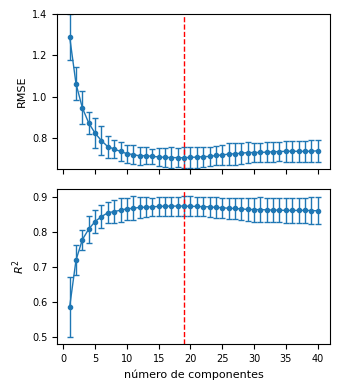

In [143]:
fig, axs = plt.subplots(2, 1, figsize=(3.5, 4), sharex=True)
for ax, M, rotulo in [(axs[0], R_pls, 'RMSE'), (axs[1], Q_pls, '$R^2$')]:
    ax.errorbar(ks, M.mean(axis=1), yerr=M.std(axis=1, ddof=1), fmt='o-', ms=3, lw=1, capsize=2)
    ax.axvline(k_otimo, color='red', ls='--', lw=1)
    ax.set_ylabel(rotulo, fontsize=8); ax.tick_params(labelsize=7)
axs[0].set_ylim(0.65, 1.4)     # o ponto com 1 componente (1.29) domina a escala; ajuste se preferir
axs[1].set_xlabel('número de componentes', fontsize=8)
plt.tight_layout()
plt.savefig('fig_cv_pls.pdf', bbox_inches='tight')
plt.show()

In [144]:
modelo_pls = pls_ajustar(Xtr, ytr, k_otimo)
p_pls = ridge_prever(modelo_pls, Xte)
print('treino RMSE: %.4f' % rmse(ytr, ridge_prever(modelo_pls, Xtr)))
print('teste  RMSE: %.4f | R2: %.4f' % (rmse(yte, p_pls), r2(yte, p_pls)))

treino RMSE: 0.5384
teste  RMSE: 0.7337 | R2: 0.8750


In [145]:
mu, sd = padronizar_ajustar(Xtr)
pl = PLSRegression(n_components=k_otimo, scale=False).fit((Xtr - mu) / sd, ytr)
p_sk = pl.predict((Xte - mu) / sd).ravel()
print('sklearn teste | RMSE: %.4f | R2: %.4f' % (rmse(yte, p_sk), r2(yte, p_sk)))
print('maior diferença nas predições:', np.abs(p_sk - p_pls).max())

# Conferência da validação cruzada, em todo o intervalo de componentes
R_sk = np.zeros_like(R_pls)
for i, k in enumerate(ks):
    for j, (idx_tr, idx_va) in enumerate(folds):
        mu_f, sd_f = padronizar_ajustar(Xtr[idx_tr])
        pl_f = PLSRegression(n_components=k, scale=False).fit((Xtr[idx_tr] - mu_f) / sd_f, ytr[idx_tr])
        R_sk[i, j] = rmse(ytr[idx_va], pl_f.predict((Xtr[idx_va] - mu_f) / sd_f).ravel())
print('maior diferença no perfil de CV:', np.abs(R_sk - R_pls).max())

sklearn teste | RMSE: 0.7337 | R2: 0.8750
maior diferença nas predições: 1.3322676295501878e-14
maior diferença no perfil de CV: 2.6645352591003757e-15


#ITEM 4

In [146]:
from sklearn.neural_network import MLPRegressor
import warnings; warnings.filterwarnings('ignore')

def nn_ajustar(X, y, h, alpha, sementes=(0, 1, 2)):
    mu, sd = padronizar_ajustar(X)               # padronização só com o treino
    Z = (X - mu) / sd
    ym, ys = y.mean(), y.std()                   # a resposta também é padronizada
    redes = [MLPRegressor(hidden_layer_sizes=(h,), alpha=alpha, solver='lbfgs',
                          max_iter=300, random_state=s).fit(Z, (y - ym) / ys)
             for s in sementes]
    return {'redes': redes, 'mu': mu, 'sd': sd, 'ym': ym, 'ys': ys}

def nn_prever(m, X):
    Z = (X - m['mu']) / m['sd']
    return np.mean([r.predict(Z) for r in m['redes']], axis=0) * m['ys'] + m['ym']

In [147]:
import time
hs, alfas = [3, 5, 10], [3, 10, 30]
res = {}
t0 = time.time()
for h in hs:
    for a in alfas:
        res[(h, a)] = np.array([rmse(ytr[va], nn_prever(nn_ajustar(Xtr[tr], ytr[tr], h, a), Xtr[va]))
                                for tr, va in folds])
        print(h, a, round(res[(h, a)].mean(), 4), f'{time.time() - t0:.0f}s')

melhor = min(res, key=lambda k: res[k].mean())
print('melhor (h, alpha):', melhor, '| RMSE CV: %.4f (dp %.4f)' % (res[melhor].mean(), res[melhor].std(ddof=1)))

3 3 0.6919 58s
3 10 0.6493 114s
3 30 0.6441 171s
5 3 0.6502 225s
5 10 0.6084 279s
5 30 0.6269 336s
10 3 0.6358 398s
10 10 0.6066 459s
10 30 0.6257 520s
melhor (h, alpha): (10, 10) | RMSE CV: 0.6066 (dp 0.0443)


In [148]:
modelo_rna = nn_ajustar(Xtr, ytr, *melhor)
p_rna = nn_prever(modelo_rna, Xte)
print('treino RMSE: %.4f' % rmse(ytr, nn_prever(modelo_rna, Xtr)))
print('teste  RMSE: %.4f | R2: %.4f' % (rmse(yte, p_rna), r2(yte, p_rna)))

treino RMSE: 0.2399
teste  RMSE: 0.6273 | R2: 0.9086


In [149]:
from scipy.stats import ttest_rel, wilcoxon

rmse_ols   = cv_ols(Xtr, ytr, folds)[0]
rmse_ridge = R[R.mean(axis=1).argmin()]        # R: matriz λ × folds do item 2
rmse_pls   = R_pls[R_pls.mean(axis=1).argmin()]
rmse_rna   = res[melhor]

for nome, v in {'OLS': rmse_ols, 'Ridge': rmse_ridge, 'PLS': rmse_pls}.items():
    print('%-5s vs RNA | dif média: %.4f | t pareado p=%.4f | Wilcoxon p=%.4f' %
          (nome, (v - rmse_rna).mean(), ttest_rel(v, rmse_rna).pvalue, wilcoxon(v, rmse_rna).pvalue))

OLS   vs RNA | dif média: 0.1213 | t pareado p=0.0000 | Wilcoxon p=0.0020
Ridge vs RNA | dif média: 0.0793 | t pareado p=0.0003 | Wilcoxon p=0.0020
PLS   vs RNA | dif média: 0.0986 | t pareado p=0.0000 | Wilcoxon p=0.0020
